# 08 发生率预报：网格定义、事件归属与阳性率

BNBU DS 2043 / DI-3。本笔记本只建立 **2° × 30 天** 网格，把已核定的 USGS 1965–2024 M≥5.5 目录及后期 2025–2026 holdout 归入格窗，并报告计数与阳性率。

**不做的事：** 不训练任何机器学习模型；不改写 `07_external/catalogs`、`latest_cleaned`、队友 zip、旧笔记本或地图；不推送 GitHub。

运行目录：`/workspace/08_rate_forecast/`。共同函数在 `rate_forecast_lib.py`。

## 0 已锁定的合同

- **主目录：** USGS 1965–2024、M≥5.5 地震。官方候选表 `catalog_1965_2024_cleaned.csv` 的 sha256 为 `1018e3856fcf15c791f4136fb833f0b4937868e3e6c1f54ead6503529289f265`。本机若无该文件，则用本地四窗目录按同一过滤重建，并用 `/workspace/07_ml_readiness/usgs2024_event_membership.csv` 的区域标记。必须再现 28,044 / 矩形 4,220 / Pacific 2,188 / 交 74 / 并 6,334，否则停止，不改区域定义。
- **研究区：** 闭矩形 70–145°E、10–60°N（含边界）与 PB2002 Pacific 多边形（仅 within，无 nearest 填充）的并集；交集事件只计一次。
- **目标：** 每个时空格的 \(P(N \ge 1)\)，即该 30 天窗内至少发生一次研究区内 M≥5.5 地震。期望计数只作诊断。
- **时间窗：** 从 `1965-01-01T00:00:00Z` 起的固定 30 天箱，不是日历月。事件按发震时刻归入 \([t_s, t_e)\)。
- **分段归属：** 一个时间窗只有在整段都落在分段内时才属于该分段。
  - 训练 \([1965-01-01,\ 2009-01-01)\)
  - 验证 \([2009-01-01,\ 2017-01-01)\)
  - 测试 \([2017-01-01,\ 2025-01-01)\)
  - 后期 holdout \([2025-01-01,\ 2026-11-26T07:43:30Z]\)（官方抓取终点，不外推）。
- **空间网格：** 全球 2° 网格，对齐偶度数；经度先卷到 \([-180,\ 180)\)；格单元为 \([2k,\ 2k+2)\)。日界线两侧的 \([178,\ 180)\) 与 \([-180,\ -178)\) 保持为两个格子，不合并。掩膜为「按赋值规则能装下至少一个研究区点」的格子。
- **历史活动格子：** 训练期 \([1965-01-01,\ 2009-01-01)\) 内该区域至少有一条事件落入该格（含跨段窗中仍早于 2009-01-01 的事件）。
- 2025–2026 不得混入 1965–2024 主表，也不得进入训练/验证/测试的标签集。

In [1]:
%matplotlib inline
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

from rate_forecast_lib import (
    LOCK_COUNTS, HOLDOUT_LOCK, CountMismatchError,
    load_and_verify_catalog, build_windows, build_cell_mask,
    assign_events, mark_historical_activity, summarize_counts,
    boundary_event_counts,
)
from rate_forecast_plots import (
    FIG, plot_cell_mask, plot_hist_active, plot_prevalence, plot_positive_series,
)

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)
ROOT = Path("/workspace/08_rate_forecast")
FIG.mkdir(parents=True, exist_ok=True)
print("working dir", ROOT)

working dir /workspace/08_rate_forecast


## 1 读取并核对主目录

四窗过滤与此前官方交叉核对相同：`type` 不区分大小写等于 `earthquake`，`mag >= 5.5`，时间 UTC 含 1965-01-01、不含 2025-01-01，按 `id` 去重（保留最早时刻）。区域标记直接使用已核定的 membership 表，不重做板块归属。

In [2]:
try:
    ev_main, ev_hold = load_and_verify_catalog()
except CountMismatchError as exc:
    raise SystemExit(f"STOP: counts disagree with the locked region definition.\n{exc}")

got = {
    "all": len(ev_main),
    "china_rectangle": int(ev_main.china_rectangle.sum()),
    "PB_Pacific": int(ev_main.PB_Pacific.sum()),
    "overlap": int((ev_main.china_rectangle & ev_main.PB_Pacific).sum()),
    "union": int(ev_main.in_union.sum()),
}
print("1965-2024 reconstructed counts:", got)
print("locked:", LOCK_COUNTS)
print("match:", got == LOCK_COUNTS)
print("holdout all/union:", len(ev_hold), int(ev_hold.in_union.sum()), "locked", HOLDOUT_LOCK)
print("main time:", ev_main.time_utc.min(), "->", ev_main.time_utc.max())
print("holdout time:", ev_hold.time_utc.min(), "->", ev_hold.time_utc.max())
print("id overlap main vs holdout:", len(set(ev_main.id) & set(ev_hold.id)))
ev_all = pd.concat([ev_main, ev_hold], ignore_index=True)
print("union events total (main+holdout):", int(ev_all.in_union.sum()))

1965-2024 reconstructed counts: {'all': 28044, 'china_rectangle': 4220, 'PB_Pacific': 2188, 'overlap': 74, 'union': 6334}
locked: {'all': 28044, 'china_rectangle': 4220, 'PB_Pacific': 2188, 'overlap': 74, 'union': 6334}
match: True
holdout all/union: 949 190 locked {'all': 949, 'union': 190}
main time: 1965-01-01 21:38:31.360000+00:00 -> 2024-12-30 05:41:06.678000+00:00
holdout time: 2025-01-01 04:39:18.208000+00:00 -> 2026-11-25 01:38:45.672000+00:00
id overlap main vs holdout: 0
union events total (main+holdout): 6524


## 2 固定 30 天时间窗与分段

窗 \(i\) 为 \([t_0 + 30i,\ t_0 + 30(i+1))\) 天，\(t_0=\) 1965-01-01T00:00:00Z。跨段窗与越过抓取终点的最后不完整 holdout 窗不进入任一评分分段，但其内事件在后续窗开始之后仍可作为历史（仅对发震时刻早于该窗起点的事件）。

In [3]:
windows = build_windows()
print(windows.groupby(["split", "boundary_note"]).size().rename("n_windows"))
print()
print("windows not assigned to a split:")
print(
    windows.loc[windows.split == "none", ["window_id", "window_start", "window_end", "boundary_note"]]
    .to_string(index=False)
)
print()
print("complete-split window counts:", windows.loc[windows.entirely_in_split, "split"].value_counts().to_dict())

split    boundary_note        
holdout  holdout                   22
none     incomplete_holdout         1
         straddle_test_holdout      1
         straddle_train_val         1
         straddle_val_test          1
test     test                      96
train    train                    535
val      val                       97
Name: n_windows, dtype: int64

windows not assigned to a split:
 window_id              window_start                window_end         boundary_note
       535 2008-12-11 00:00:00+00:00 2009-01-10 00:00:00+00:00    straddle_train_val
       633 2016-12-29 00:00:00+00:00 2017-01-28 00:00:00+00:00     straddle_val_test
       730 2024-12-17 00:00:00+00:00 2025-01-16 00:00:00+00:00 straddle_test_holdout
       753 2026-11-07 00:00:00+00:00 2026-12-07 00:00:00+00:00    incomplete_holdout

complete-split window counts: {'train': 535, 'val': 97, 'test': 96, 'holdout': 22}


## 3 2° 空间网格与研究区掩膜

**赋值规则（精确）：**

1. 经度先映射到 \([-180,\ 180)\)：`lon_wrapped = (lon + 180) mod 360 - 180`，因此 180° 记为 -180°。
2. 格西缘 `2 * floor(lon_wrapped / 2)`，格南缘 `2 * floor(lat / 2)`；格单元是半开区间 `[west, west+2) × [south, south+2)`。
3. 闭矩形上的点（含 lon=145、lat=60）按上述规则落入格子后，这些格子全部进入矩形掩膜。因此矩形为 38×26=988 格，含 `[144,146)×[60,62)` 这一行一列。
4. Pacific 掩膜：PB2002 Pacific 经 `make_valid` 并按 `PlateName` dissolve；原始几何已在日界线处分成三块，不把 \([178,180)\) 与 \([-180,-178)\) 合成一格。用半开格盒与各块做相交测试。
5. 并集掩膜 = 矩形或 Pacific。格中心取西缘+1°、南缘+1°，仅用于作图与后续核平滑。

这是等经纬度网格，不是等面积网格。

in_union_mask           3594
intersects_rectangle     988
intersects_pacific      2632
dtype: int64
geometry overlap cells: 26
union identity 988 + 2632 - overlap = 3594
lon_west range: -180 178
lat_south range: -68 60
dateline edge cells [-180,-178) or [178,180): 101


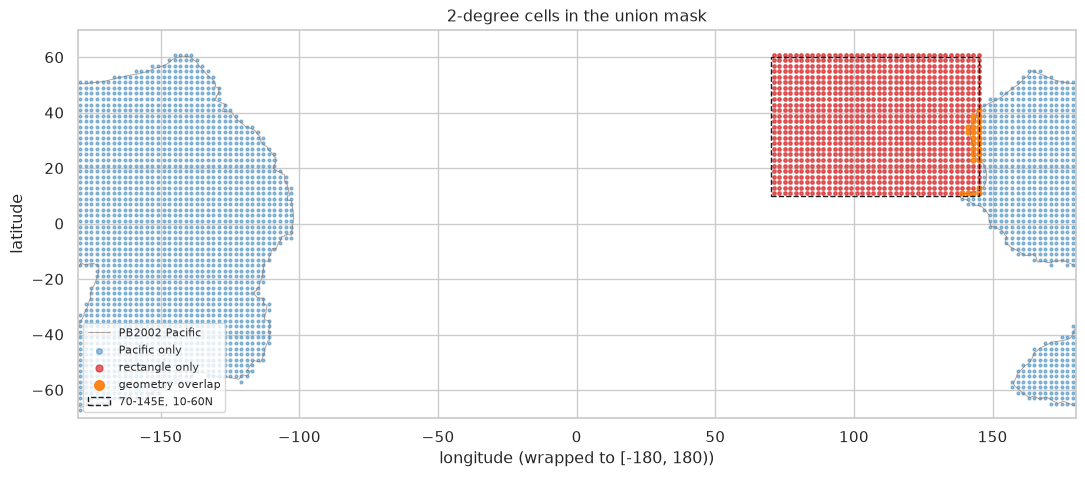

In [4]:
cells = build_cell_mask()
print(cells.agg({
    "in_union_mask": "sum",
    "intersects_rectangle": "sum",
    "intersects_pacific": "sum",
}))
n_overlap = int((cells.intersects_rectangle & cells.intersects_pacific).sum())
print("geometry overlap cells:", n_overlap)
print("union identity 988 + 2632 - overlap =", 988 + int(cells.intersects_pacific.sum()) - n_overlap)
print("lon_west range:", int(cells.lon_west.min()), int(cells.lon_west.max()))
print("lat_south range:", int(cells.lat_south.min()), int(cells.lat_south.max()))
print("dateline edge cells [-180,-178) or [178,180):",
      int(((cells.lon_west == -180) | (cells.lon_west == 178)).sum()))
fig = plot_cell_mask(cells, FIG / "grid_mask_cells.png")
plt.show()
plt.close(fig)

## 4 把事件归入格窗

只把研究区（并集）事件当作本任务的阳性来源。一条并集事件必须落到并集掩膜中，否则停止。后期 holdout 事件同样归格，但不进入 1965–2024 主计数。

union events outside mask: 0
historically active cells (train-period origin time):
historically_active_rectangle    327
historically_active_pacific      224
historically_active_union        538
dtype: int64

union events by catalog role and split (complete windows vs excluded):
catalog_role             split  
later_holdout_2025_2026  holdout     178
                         none         12
main_1965_2024           none         18
                         test        633
                         train      4553
                         val        1130
Name: n, dtype: int64
saved windows.csv, cells_mask.csv, events_union_assigned.csv


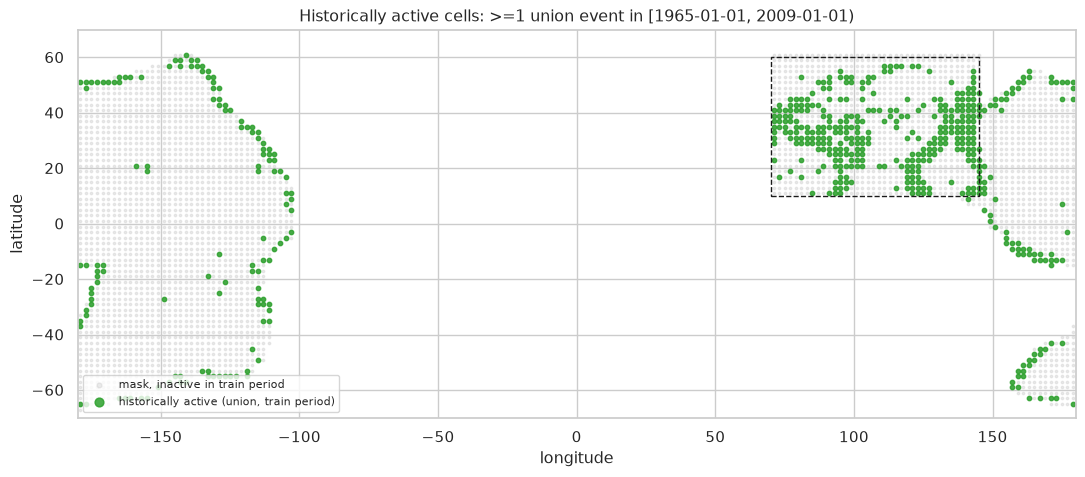

In [5]:
ev = assign_events(ev_all, windows)
cells = mark_historical_activity(cells, ev)
union = ev.loc[ev.in_union]
missing = union.loc[~union.cell_id.isin(set(cells.loc[cells.in_union_mask, "cell_id"]))]
print("union events outside mask:", len(missing))
if len(missing):
    raise SystemExit("STOP: assignment left union events outside the mask")
print("historically active cells (train-period origin time):")
print(cells[["historically_active_rectangle", "historically_active_pacific", "historically_active_union"]].sum())
print()
print("union events by catalog role and split (complete windows vs excluded):")
print(union.groupby(["catalog_role", "split"], dropna=False).size().rename("n"))
# persist the same artifacts the pipeline writes
windows.to_csv(ROOT / "windows.csv", index=False)
cells.to_csv(ROOT / "cells_mask.csv", index=False)
union.to_csv(ROOT / "events_union_assigned.csv", index=False)
print("saved windows.csv, cells_mask.csv, events_union_assigned.csv")
fig = plot_hist_active(cells, FIG / "grid_hist_active_cells.png")
plt.show()
plt.close(fig)

## 5 计数与阳性率

每一行是「区域 × 分段」。区域评分只用该区域的掩膜格和该区域的事件：矩形事件给矩形，Pacific 事件给 Pacific，并集事件给并集。阳性格窗 = 该窗该格至少一条相应区域事件。

评价集 1：区域掩膜中的全部格子。评价集 2：训练期内有过至少一条相应区域事件的格子。阳性率 = 阳性格窗 / (格数 × 完整窗数)。不用准确率。

,region,split,n_cells_all,n_windows,n_cell_windows_all,n_events_in_complete_windows,n_positive_cell_windows_all,prevalence_all,n_cells_hist_active,n_cell_windows_hist_active,n_positive_cell_windows_hist_active,prevalence_hist_active,n_unique_positive_cells_in_split
0,china_rectangle,train,988,535,528580,3056,2385,0.004512,327,174945,2385,0.013633,327
1,china_rectangle,val,988,97,95836,725,427,0.004456,327,31719,413,0.013021,142
2,china_rectangle,test,988,96,94848,430,357,0.003764,327,31392,339,0.010799,135
3,china_rectangle,holdout,988,22,21736,120,93,0.004279,327,7194,90,0.012510,57
4,pacific,train,2632,535,1408120,1526,1152,0.000818,224,119840,1152,0.009613,224
5,pacific,val,2632,97,255304,435,270,0.001058,224,21728,249,0.011460,108
6,pacific,test,2632,96,252672,218,199,0.000788,224,21504,171,0.007952,106
7,pacific,holdout,2632,22,57904,59,54,0.000933,224,4928,49,0.009943,40
8,union,train,3594,535,1922790,4553,3509,0.001825,538,287830,3509,0.012191,538
9,union,val,3594,97,348618,1130,683,0.001959,538,52186,651,0.012475,244


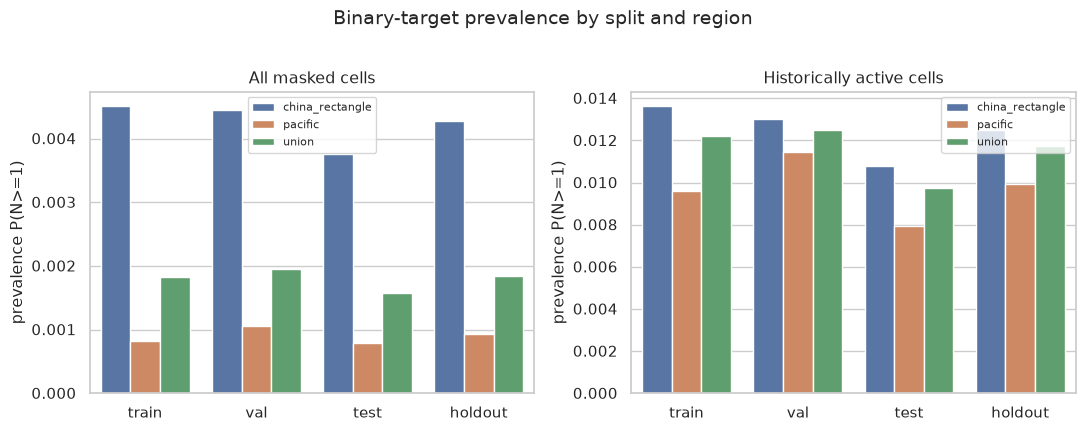

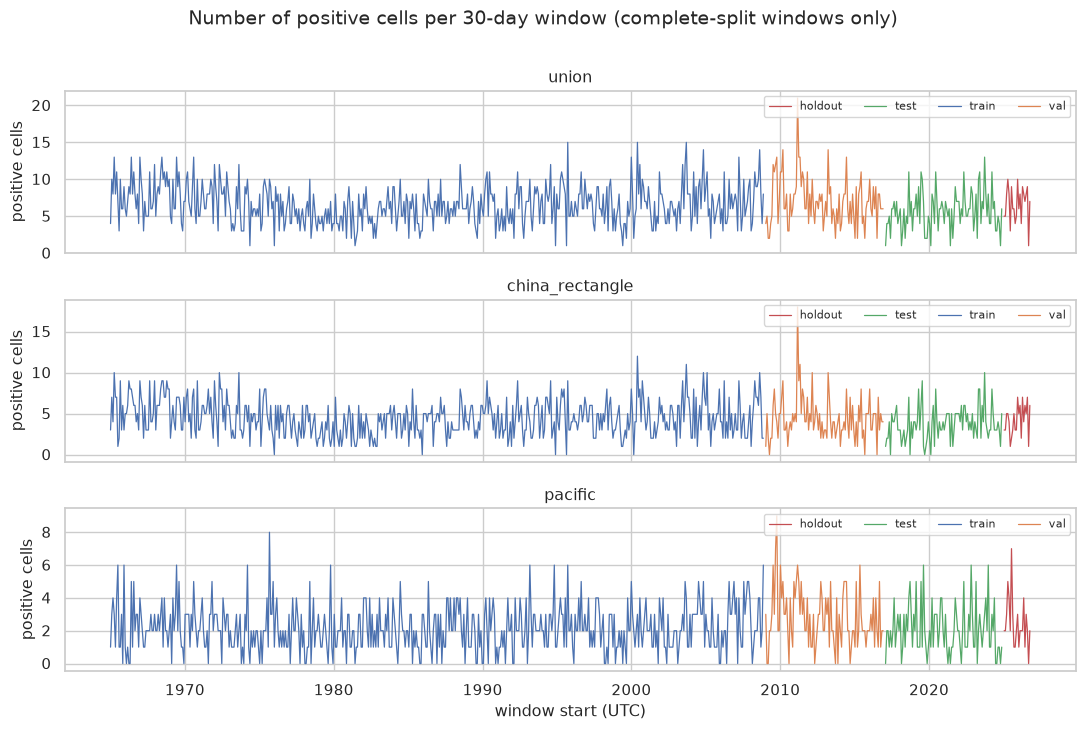

In [6]:
prev = summarize_counts(ev, windows, cells)
prev.to_csv(ROOT / "prevalence_by_split_region.csv", index=False)
display(prev)
fig = plot_prevalence(prev, FIG / "grid_prevalence_bars.png")
plt.show()
plt.close(fig)

# observed positive-cell series from complete-split windows (union-file events)
recs = []
for region, flag in [("china_rectangle", "china_rectangle"), ("pacific", "PB_Pacific"), ("union", "in_union")]:
    sub = ev.loc[ev[flag] & ev.entirely_in_split]
    g = sub.groupby(["split", "window_id"], as_index=False).agg(n_events=("id", "size"), n_positive_cells=("cell_id", "nunique"))
    g["region"] = region
    recs.append(g)
series = pd.concat(recs, ignore_index=True)
# fill windows with zero positives
full = []
for region in ["china_rectangle", "pacific", "union"]:
    w = windows.loc[windows.entirely_in_split, ["window_id", "split"]].copy()
    w["region"] = region
    full.append(w)
gridw = pd.concat(full, ignore_index=True)
series = gridw.merge(series, on=["region", "split", "window_id"], how="left")
series["n_events"] = series["n_events"].fillna(0).astype(int)
series["n_positive_cells"] = series["n_positive_cells"].fillna(0).astype(int)
series.to_csv(ROOT / "window_observed_series.csv", index=False)
fig = plot_positive_series(series, windows, FIG / "grid_positive_cells_series.png")
plt.show()
plt.close(fig)


## 6 跨段窗与未计入标签的事件

这些事件**不是**被丢弃：它们不构成该分段的标签，但只要发震时刻早于后续窗的起点，就会进入后续窗的历史。

In [7]:
bnd = boundary_event_counts(ev, windows)
display(bnd.drop(columns=["window_ids"]))
ex = windows.loc[windows.split == "none", ["window_id", "window_start", "window_end", "boundary_note"]]
for row in ex.itertuples(index=False):
    g = union.loc[union.window_id == row.window_id]
    print(
        f"{row.boundary_note}  window {row.window_id}  {row.window_start} -> {row.window_end}  "
        f"union={len(g)} rect={int(g.china_rectangle.sum())} pac={int(g.PB_Pacific.sum())}  "
        f"main={int((g.catalog_role=='main_1965_2024').sum())} holdout={int((g.catalog_role=='later_holdout_2025_2026').sum())}"
    )

print()
print("Sanity vs calendar-year period-B event totals (4558 / 1133 / 643), which used year membership rather than complete 30-day windows:")
print("complete-window union events train/val/test = 4553 / 1130 / 633; the 18 remaining main union events sit in the three straddle windows (5+3+10 by period).")
print("holdout union 190 = 178 in 22 complete holdout windows + 5 in the test/holdout straddle (2025 part) + 7 in the incomplete last window after 2026-11-07.")

,boundary_note,n_union_events,n_rectangle,n_pacific
0,holdout,178,120,59
1,incomplete_holdout,7,5,2
2,straddle_test_holdout,7,6,1
3,straddle_train_val,8,5,3
4,straddle_val_test,8,2,6
5,test,633,430,218
6,train,4553,3056,1526
7,val,1130,725,435


straddle_train_val  window 535  2008-12-11 00:00:00+00:00 -> 2009-01-10 00:00:00+00:00  union=8 rect=5 pac=3  main=8 holdout=0
straddle_val_test  window 633  2016-12-29 00:00:00+00:00 -> 2017-01-28 00:00:00+00:00  union=8 rect=2 pac=6  main=8 holdout=0
straddle_test_holdout  window 730  2024-12-17 00:00:00+00:00 -> 2025-01-16 00:00:00+00:00  union=7 rect=6 pac=1  main=2 holdout=5
incomplete_holdout  window 753  2026-11-07 00:00:00+00:00 -> 2026-12-07 00:00:00+00:00  union=7 rect=5 pac=2  main=0 holdout=7

Sanity vs calendar-year period-B event totals (4558 / 1133 / 643), which used year membership rather than complete 30-day windows:
complete-window union events train/val/test = 4553 / 1130 / 633; the 18 remaining main union events sit in the three straddle windows (5+3+10 by period).
holdout union 190 = 178 in 22 complete holdout windows + 5 in the test/holdout straddle (2025 part) + 7 in the incomplete last window after 2026-11-07.


## 产出文件

- `windows.csv`，`cells_mask.csv`，`events_union_assigned.csv`
- `prevalence_by_split_region.csv`，`boundary_window_event_counts.csv`，`counts_summary.json`
- 图：`figures/grid_mask_cells.png`，`figures/grid_hist_active_cells.png`，`figures/grid_prevalence_bars.png`，`figures/grid_positive_cells_series.png`

基线与评分在 `08_rate_forecast_baselines.ipynb`。